# AAEC vs ARIES — Comparative Analysis
### Notebook 03 · Why do isolated nodes exist? What does ARIES lose from AAEC?

**Goal:** Compare the AAEC original annotation with its ARIES representation to understand:
1. What information ARIES preserves and what it loses
2. Why some ADUs appear as isolated nodes in ARIES graphs
3. Whether the edge direction in ARIES matches the original AAEC direction

**AAEC original structure (Stab & Gurevych, 2017):**
```
essay.txt  → raw persuasive essay text
essay.ann  → brat standoff annotations
             T1  MajorClaim  char_start char_end  'text'
             T2  Claim       char_start char_end  'text'
             T3  Premise     char_start char_end  'text'
             R1  supports    Arg1:T3  Arg2:T2    (T3 supports T2)
             R2  attacks     Arg1:T2  Arg2:T1    (T2 attacks T1)
             A1  Stance      T1  For
```

**Key structural difference:**
```
AAEC:   Premise ──supports──► Claim ──supports──► MajorClaim
        (bottom-up: evidence → conclusion)

ARIES:  ADU_pair → Inference(1) / Conflict(2) / Neutral(0)
        (direction to verify, component types lost)
```


---
## 0 · Setup


In [1]:
import subprocess, sys
PKGS = ['pandas','numpy','matplotlib','seaborn','networkx','tabulate','tqdm']
subprocess.run([sys.executable,'-m','pip','install','--quiet']+PKGS)
print('Dependencies installed')

Dependencies installed


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import networkx as nx
from tabulate import tabulate
from tqdm import tqdm
from pathlib import Path
from collections import defaultdict
import re, ast, warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams.update({
    'figure.facecolor':'#ffffff','axes.facecolor':'#ffffff',
    'axes.edgecolor':'#000000','axes.labelcolor':'#000000',
    'xtick.color':'#000000','ytick.color':'#000000',
    'text.color':'#000000','grid.color':'#cccccc',
    'grid.linewidth':0.5,'figure.dpi':110,
})
PALETTE    = ['#5b8dee','#f06060','#3ecf8e','#f0a500','#7c5ce6','#a29bfe']
REL_COLOR  = {1:'#5b8dee', 2:'#f06060'}
REL_LBL    = {1:'Inference', 2:'Conflict'}
COMP_COLOR = {'MajorClaim':'#f0a500','Claim':'#5b8dee',
              'Premise':'#3ecf8e','Unknown':'#cccccc'}

print('Imports OK')


Imports OK


---
## 1 · Configure paths and extract AAEC from ARIES CSV


In [3]:
# ── CONFIGURE ────────────────────────────────────────────────────────────
ARIES_CSV = '../data/aries/data.csv'      # <-- ARIES benchmark CSV
AAEC_DIR  = Path('../data/aaec/')         # <-- folder with essay001.ann / .txt

COL = {
    'argument': 'argument',
    'p1':       'proposition_1',
    'p2':       'proposition_2',
    'relation': 'relations',
    'dataset':  'data_source',
    'all_rel':  'all_relations',
    'indexes':  'start_end_indexes',
}
CORPUS_NAMES = {
    'Cuties':'QT30',
    'US2016R1':'US2016_Reddit',
    'Microtext':'MTC',
    'ABstRACT':'AbstRCT',
}


In [9]:
# ── Load + normalise ARIES CSV ───────────────────────────────────────────
df_raw = pd.read_csv(ARIES_CSV, sep=',', dtype=str, keep_default_na=False)
df_raw['relations'] = pd.to_numeric(df_raw['relations'], errors='coerce')
df_raw['corpus']    = df_raw[COL['dataset']].replace(CORPUS_NAMES)

# Strip whitespace from P1 and P2 (P2 has leading/trailing spaces — CSV artifact)
df_raw[COL['p1']] = df_raw[COL['p1']].str.strip()
df_raw[COL['p2']] = df_raw[COL['p2']].str.strip()

# Remove auto-arcs
df_all  = df_raw[df_raw[COL['p1']] != df_raw[COL['p2']]].copy()

# Extract AAEC subset
df_aaec = df_all[df_all['corpus'] == 'AAEC'].copy().reset_index(drop=True)


unique_adus = pd.concat([df_aaec[COL['p1']], df_aaec[COL['p2']]]).unique()

n_essays = df_aaec[COL['argument']].nunique()
n_pairs  = len(df_aaec)
n_real   = (df_aaec[COL['relation']] != 0).sum()

print('AAEC subset in ARIES:')
print(f'  Essays (unique arguments) : {n_essays:>5,}')
print(f'  ADU pairs (rows)          : {n_pairs:>5,}')
print(f'  Relations (non-Neutral)   : {n_real:>4,}  ({100*n_real/n_pairs:.1f}%)')
print(f'  Unique propositions       : {len(unique_adus):>5,}')
print()
print('Relation distribution:')
for k,v in df_aaec[COL['relation']].value_counts().sort_index().items():
    lbl = {0:'Neutral  ',1:'Inference',2:'Conflict '}[int(k)]
    print(f'  {lbl} ({int(k)}): {v:>5,}  ({100*v/n_pairs:.1f}%)')


AAEC subset in ARIES:
  Essays (unique arguments) :   402
  ADU pairs (rows)          : 15,217
  Relations (non-Neutral)   : 5,338  (35.1%)
  Unique propositions       : 5,992

Relation distribution:
  Neutral   (0): 9,879  (64.9%)
  Inference (1): 4,841  (31.8%)
  Conflict  (2):   497  (3.3%)


In [8]:
# ── Inspect one essay ────────────────────────────────────────────────────
sample_arg = df_aaec[COL['argument']].iloc[0]
print("Sample argument: ", sample_arg)
subset_ex  = df_aaec[df_aaec[COL['argument']] == sample_arg]


all_adus = pd.concat([subset_ex[COL['p1']], subset_ex[COL['p2']]]).unique()
print(f'Sample essay ADUs ({len(all_adus)} total):')
for i, adu in enumerate(all_adus):
    print(f'  ADU{i+1}: {adu}')
print()
print('Non-Neutral pairs:')
for _, row in subset_ex[subset_ex[COL['relation']] != 0].iterrows():
    lbl = REL_LBL[int(row[COL['relation']])]
    print(f'  P1: "{row[COL["p1"]][:60]}"')
    print(f'  P2: "{row[COL["p2"]][:60]}"  → {lbl}')
    print()


Sample argument:   reducing stress by listening to music, playing sports, and doing meditation are easy and practical ways '[SEP]' I always listen music from my mp3 player '[SEP]' I could enjoy listening music without thinking of people around me '[SEP]' I feel happy when I listen music '[SEP]' listening to music is a great way to relax '[SEP]' another way that is perfectly work for everyone to reduce the stress is exercise '[SEP]' after work, I always do exercise, and jogging is my favorite sport '[SEP]' I feel that after working out, I am easily to fall asleep '[SEP]' Exercising not only reduce my stress but also make me get a good health '[SEP]' Meditation is easy way to relax '[SEP]' it is not require any equipment, and it take few minutes '[SEP]' A way to do meditation is that I just sit down, close my eyes, and count my breath '[SEP]' These could relieve me from stress '[SEP]' meditation also one of the ways to reduce the stress '[SEP]' listening to music, exercising, and doing m

In [10]:
def get_sentences_from_argument(sample_arg, split_char='[SEP]'):
    """
    Given a sample argument string, split it into individual sentences based on the specified split character.
    Returns a dictionary mapping sentence keys (S1, S2, ...) to their corresponding sentences.
    """
    sample_sentences = sample_arg.split(f"'{split_char}'")
    dic_sentences = {f"S{i+1}": sentence.strip() for i, sentence in enumerate(sample_sentences)}

    print("Sample Sentences Dictionary (split by '[SEP]'):")
    for key, sentence in dic_sentences.items():
        print(f"{key}: {sentence}")
    
    return dic_sentences

dic_sentences = get_sentences_from_argument(sample_arg)


Sample Sentences Dictionary (split by '[SEP]'):
S1: reducing stress by listening to music, playing sports, and doing meditation are easy and practical ways
S2: I always listen music from my mp3 player
S3: I could enjoy listening music without thinking of people around me
S4: I feel happy when I listen music
S5: listening to music is a great way to relax
S6: another way that is perfectly work for everyone to reduce the stress is exercise
S7: after work, I always do exercise, and jogging is my favorite sport
S8: I feel that after working out, I am easily to fall asleep
S9: Exercising not only reduce my stress but also make me get a good health
S10: Meditation is easy way to relax
S11: it is not require any equipment, and it take few minutes
S12: A way to do meditation is that I just sit down, close my eyes, and count my breath
S13: These could relieve me from stress
S14: meditation also one of the ways to reduce the stress
S15: listening to music, exercising, and doing meditation are the

---
## 2 · Load AAEC original (.ann files)

If you don't have the AAEC files, download from:
https://github.com/philippStab/argumentative-essays

Set `AAEC_DIR` in Section 1 to the folder containing the `.ann` / `.txt` files.


In [14]:
def parse_ann_file(ann_path, txt_path=None):
    """
    Parse a brat .ann file from AAEC.
    Returns:
        components : dict {T_id -> {type, start, end, text}}
        relations  : list of {rel_id, rel_type, source, target}
        stance     : str or None
    """
    components, relations = {}, []
    stance = None
    raw_text = ''
    if txt_path and Path(txt_path).exists():
        raw_text = Path(txt_path).read_text(encoding='utf-8')

    with open(ann_path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split('\t')

            if parts[0].startswith('T') and len(parts) >= 2:
                t_id = parts[0]
                meta = parts[1].split()
                c_type  = meta[0]
                c_start = int(meta[1])
                c_end   = int(meta[-1])
                c_text  = parts[2].strip() if len(parts) > 2 else (
                          raw_text[c_start:c_end] if raw_text else '')
                components[t_id] = {
                    'type': c_type, 'start': c_start,
                    'end':  c_end,  'text':  c_text,
                }

            elif parts[0].startswith('R') and len(parts) >= 2:
                meta   = parts[1].split()
                r_type = meta[0]
                source = meta[1].split(':')[1]
                target = meta[2].split(':')[1]
                relations.append({
                    'rel_id': parts[0], 'rel_type': r_type,
                    'source': source,   'target':   target,
                })

            elif parts[0].startswith('A') and len(parts) >= 2:
                meta = parts[1].split()
                if meta[0] == 'Stance' and len(meta) > 2:
                    stance = meta[2]

    return components, relations, stance


In [15]:
# ── Load all .ann files ───────────────────────────────────────────────────
ann_files = sorted(AAEC_DIR.glob('*.ann'))
print(f'Found {len(ann_files)} .ann files in {AAEC_DIR}')

aaec_essays = {}
if ann_files:
    for ann_path in tqdm(ann_files, desc='Parsing .ann files'):
        essay_id = ann_path.stem
        txt_path = ann_path.with_suffix('.txt')
        comps, rels, stance = parse_ann_file(ann_path, txt_path)
        aaec_essays[essay_id] = {
            'components': comps,
            'relations':  rels,
            'stance':     stance,
            'n_components': len(comps),
            'n_relations':  len(rels),
        }
    print(f'Loaded {len(aaec_essays)} essays')
    print(f'  Total components : {sum(e["n_components"] for e in aaec_essays.values()):,}')
    print(f'  Total relations  : {sum(e["n_relations"]  for e in aaec_essays.values()):,}')
else:
    print('No .ann files found — set AAEC_DIR correctly.')
    print('Sections 2-8 require the original AAEC files.')
    print('Section 1 (ARIES-only analysis) is still valid.')


Found 402 .ann files in ../data/aaec


Parsing .ann files:   0%|          | 0/402 [00:00<?, ?it/s]

Parsing .ann files: 100%|██████████| 402/402 [00:00<00:00, 2911.12it/s]

Loaded 402 essays
  Total components : 6,089
  Total relations  : 3,832


In [16]:
# ── Component and relation type counts ───────────────────────────────────
if aaec_essays:
    type_counts    = defaultdict(int)
    reltype_counts = defaultdict(int)
    for ed in aaec_essays.values():
        for c in ed['components'].values():
            type_counts[c['type']] += 1
        for r in ed['relations']:
            reltype_counts[r['rel_type']] += 1

    print('Component types:')
    for t,n in sorted(type_counts.items(), key=lambda x:-x[1]):
        print(f'  {t:<15s}: {n:>5,}')
    print()
    print('Relation types:')
    for t,n in sorted(reltype_counts.items(), key=lambda x:-x[1]):
        print(f'  {t:<15s}: {n:>5,}')


Component types:
  Premise        : 3,832
  Claim          : 1,506
  MajorClaim     :   751

Relation types:
  supports       : 3,613
  attacks        :   219


---
## 3 · ARIES graph reconstruction for AAEC


In [17]:
def build_aries_graph(subset):
    G = nx.DiGraph()
    all_adus = pd.concat([subset[COL['p1']], subset[COL['p2']]]).unique()
    for adu in all_adus:
        G.add_node(adu)
    for _, row in subset[subset[COL['relation']] != 0].iterrows():
        p1 = row[COL['p1']]
        p2 = row[COL['p2']]
        if p1 != p2:
            G.add_edge(p1, p2, rel=int(row[COL['relation']]))
    return G

aries_graphs = {}
for arg, grp in tqdm(df_aaec.groupby(COL['argument']),
                      desc='Building ARIES graphs'):
    aries_graphs[arg] = build_aries_graph(grp)

n_nodes_l  = [G.number_of_nodes() for G in aries_graphs.values()]
n_edges_l  = [G.number_of_edges() for G in aries_graphs.values()]
iso_l      = [sum(1 for n in G.nodes() if G.degree(n)==0)
              for G in aries_graphs.values()]

print(f'ARIES graphs built: {len(aries_graphs):,}')
print(f'  Nodes/essay  : mean={np.mean(n_nodes_l):.1f}  max={max(n_nodes_l)}')
print(f'  Edges/essay  : mean={np.mean(n_edges_l):.1f}  max={max(n_edges_l)}')
print(f'  Isolated/essay: mean={np.mean(iso_l):.2f}  total={sum(iso_l):,}')
print(f'  % isolated   : {100*sum(iso_l)/sum(n_nodes_l):.1f}%')


Building ARIES graphs: 100%|██████████| 402/402 [00:00<00:00, 910.07it/s]

ARIES graphs built: 402
  Nodes/essay  : mean=15.0  max=28
  Edges/essay  : mean=13.3  max=26
  Isolated/essay: mean=0.72  total=290
  % isolated   : 4.8%


---
## 4 · AAEC original graph reconstruction


In [18]:
def build_aaec_graph(essay_data):
    """
    Build graph from AAEC .ann data.
    Nodes: component IDs, with type and text attributes.
    Edges: source -> target as annotated (supports / attacks).
    """
    G = nx.DiGraph()
    comps = essay_data['components']
    for t_id, comp in comps.items():
        G.add_node(t_id, comp_type=comp['type'], text=comp['text'],
                   start=comp['start'], end=comp['end'])
    for rel in essay_data['relations']:
        G.add_edge(rel['source'], rel['target'], rel_type=rel['rel_type'])
    return G

if aaec_essays:
    aaec_graphs = {eid: build_aaec_graph(ed)
                   for eid, ed in aaec_essays.items()}
    n_n = [G.number_of_nodes() for G in aaec_graphs.values()]
    n_e = [G.number_of_edges() for G in aaec_graphs.values()]
    n_iso = [sum(1 for n in G.nodes() if G.degree(n)==0)
             for G in aaec_graphs.values()]
    print(f'AAEC original graphs built: {len(aaec_graphs):,}')
    print(f'  Nodes/essay  : mean={np.mean(n_n):.1f}  max={max(n_n)}')
    print(f'  Edges/essay  : mean={np.mean(n_e):.1f}  max={max(n_e)}')
    print(f'  Isolated/essay: {np.mean(n_iso):.2f} mean')
    print()
    print('Expected: very few isolated nodes in AAEC original,')
    print('because every annotated component participates in at least one relation.')


AAEC original graphs built: 402
  Nodes/essay  : mean=15.1  max=28
  Edges/essay  : mean=9.5  max=20
  Isolated/essay: 2.80 mean

Expected: very few isolated nodes in AAEC original,
because every annotated component participates in at least one relation.


---
## 5 · Side-by-side comparison (one essay)

The same essay visualised as (left) the original AAEC graph with component types
and (right) the ARIES representation with isolated nodes visible.


In [19]:
if aaec_essays:
    # Pick a small essay for clarity (4-7 components)
    sorted_essays = sorted(aaec_essays.items(), key=lambda x: x[1]['n_components'])
    target_id, target_data = next(
        ((eid,ed) for eid,ed in sorted_essays if 4 <= ed['n_components'] <= 7),
        sorted_essays[0])

    print(f'Selected essay: {target_id}')
    print(f'  Components: {target_data["n_components"]}')
    print(f'  Relations : {target_data["n_relations"]}')
    print(f'  Stance    : {target_data["stance"]}')
    print()
    print('Components:')
    for t_id, comp in sorted(target_data['components'].items()):
        print(f'  {t_id} [{comp["type"]}] "{comp["text"][:70]}"')
    print()
    print('Relations:')
    comps = target_data['components']
    for rel in target_data['relations']:
        st = comps[rel['source']]['type']
        tt = comps[rel['target']]['type']
        print(f'  {rel["source"]}({st}) ──{rel["rel_type"]}──► {rel["target"]}({tt})')


Selected essay: essay088
  Components: 7
  Relations : 2
  Stance    : For

Components:
  T1 [MajorClaim] "a defeated person has to try and try until to achieve her or his goal"
  T2 [MajorClaim] "people should not give up when they face with a failure"
  T3 [Claim] "they have to learn new points from that failure, and they become more "
  T4 [Claim] "when people face with a failure they can learn a large number of thing"
  T5 [Claim] "experience shows while people doing a job constantly, they become more"
  T6 [Premise] "most of inventors in the first phases of their job face with some prob"
  T7 [Premise] "scientists experiment a substance for a long time, after they gain lot"

Relations:
  T6(Premise) ──supports──► T4(Claim)
  T7(Premise) ──supports──► T5(Claim)


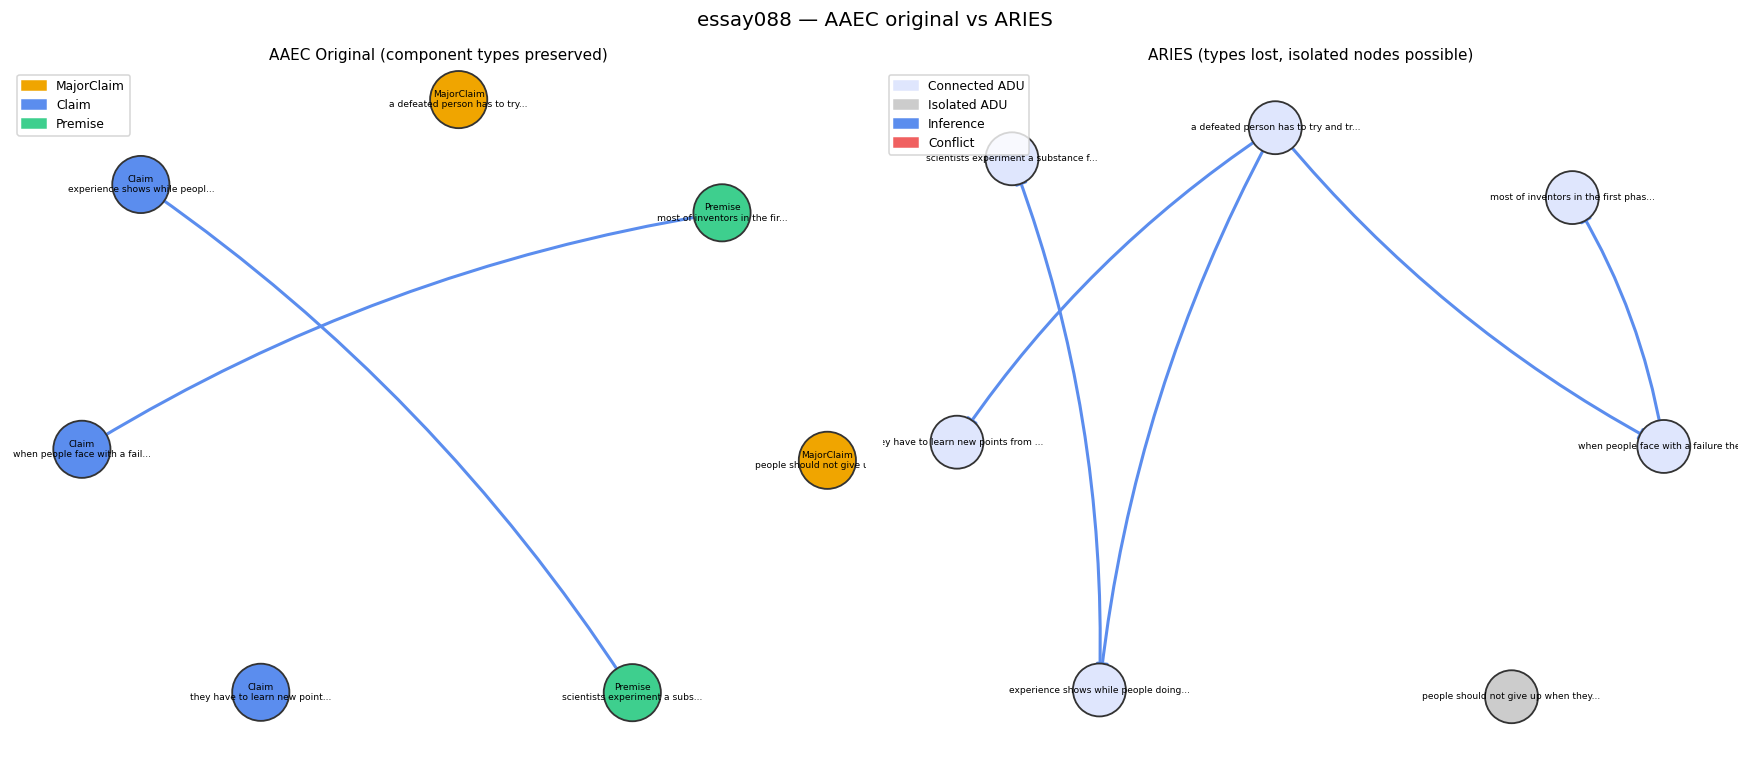

In [20]:
if aaec_essays and target_id in aaec_graphs:
    G_orig  = aaec_graphs[target_id]
    mc_text = next((c['text'] for c in target_data['components'].values()
                    if c['type']=='MajorClaim'), '')

    # Find matching ARIES graph by MajorClaim text
    aries_key, G_aries = None, None
    for arg_text, G_a in aries_graphs.items():
        if mc_text[:40] in arg_text:
            aries_key, G_aries = arg_text, G_a
            break

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle(f'{target_id} — AAEC original vs ARIES', fontsize=13)

    # LEFT: AAEC original
    ax = axes[0]
    ax.set_title('AAEC Original (component types preserved)', fontsize=10)
    pos = nx.spring_layout(G_orig, seed=42, k=3)
    nc  = [COMP_COLOR.get(G_orig.nodes[n]['comp_type'],'#cccccc') for n in G_orig.nodes()]
    lbl = {n: G_orig.nodes[n]['comp_type']+'\n'+G_orig.nodes[n]['text'][:28]+'...'
           for n in G_orig.nodes()}
    sup_e = [(u,v) for u,v,d in G_orig.edges(data=True) if d['rel_type']=='supports']
    att_e = [(u,v) for u,v,d in G_orig.edges(data=True) if d['rel_type']=='attacks']
    nx.draw_networkx_nodes(G_orig, pos, ax=ax, node_color=nc,
                           node_size=1400, edgecolors='#333', linewidths=1.2)
    nx.draw_networkx_labels(G_orig, pos, lbl, ax=ax, font_size=6)
    nx.draw_networkx_edges(G_orig, pos, edgelist=sup_e, ax=ax,
                           edge_color='#5b8dee', arrows=True, arrowsize=16,
                           width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_edges(G_orig, pos, edgelist=att_e, ax=ax,
                           edge_color='#f06060', arrows=True, arrowsize=16,
                           width=2, style='dashed', connectionstyle='arc3,rad=0.1')
    ax.legend(handles=[
        mpatches.Patch(color=COMP_COLOR['MajorClaim'], label='MajorClaim'),
        mpatches.Patch(color=COMP_COLOR['Claim'],      label='Claim'),
        mpatches.Patch(color=COMP_COLOR['Premise'],    label='Premise'),
    ], loc='upper left', fontsize=8)
    ax.axis('off')

    # RIGHT: ARIES
    ax2 = axes[1]
    ax2.set_title('ARIES (types lost, isolated nodes possible)', fontsize=10)
    if G_aries:
        pos2 = nx.spring_layout(G_aries, seed=42, k=3)
        nc2  = ['#cccccc' if G_aries.degree(n)==0 else '#dfe6fd'
                for n in G_aries.nodes()]
        lbl2 = {n: n[:35]+'...' if len(n)>35 else n for n in G_aries.nodes()}
        inf_e = [(u,v) for u,v,d in G_aries.edges(data=True) if d['rel']==1]
        con_e = [(u,v) for u,v,d in G_aries.edges(data=True) if d['rel']==2]
        nx.draw_networkx_nodes(G_aries, pos2, ax=ax2, node_color=nc2,
                               node_size=1200, edgecolors='#333', linewidths=1.2)
        nx.draw_networkx_labels(G_aries, pos2, lbl2, ax=ax2, font_size=6)
        nx.draw_networkx_edges(G_aries, pos2, edgelist=inf_e, ax=ax2,
                               edge_color='#5b8dee', arrows=True, arrowsize=16,
                               width=2, connectionstyle='arc3,rad=0.1')
        nx.draw_networkx_edges(G_aries, pos2, edgelist=con_e, ax=ax2,
                               edge_color='#f06060', arrows=True, arrowsize=16,
                               width=2, style='dashed', connectionstyle='arc3,rad=0.1')
        ax2.legend(handles=[
            mpatches.Patch(color='#dfe6fd', label='Connected ADU'),
            mpatches.Patch(color='#cccccc', label='Isolated ADU'),
            mpatches.Patch(color='#5b8dee', label='Inference'),
            mpatches.Patch(color='#f06060', label='Conflict'),
        ], loc='upper left', fontsize=8)
    else:
        ax2.text(0.5, 0.5, 'Matching ARIES essay not found\n'
                 '(check that mc_text matches argument column)',
                 ha='center', va='center', transform=ax2.transAxes)
    ax2.axis('off')
    plt.tight_layout()
    plt.savefig('fig_aaec_vs_aries.png', dpi=150, bbox_inches='tight')
    plt.show()


---
## 6 · Why do isolated nodes exist? — systematic analysis

Three hypotheses:

| # | Hypothesis | Expected signature |
|---|---|---|
| H1 | ADU is **non-argumentative text** — not annotated in AAEC | node text absent from all AAEC components |
| H2 | **Text mismatch** — ARIES has a different string than AAEC | node text present in essay but doesn't match exactly |
| H3 | **Incomplete pair generation** — ARIES only generates pairs where P1 has a real relation | some ADUs only appear as P2 targets |


In [21]:
if aaec_essays and aries_key and G_aries:
    comps_ex = target_data['components']
    aaec_texts = {c['text'].strip() for c in comps_ex.values()}

    print('Node analysis for the example essay:')
    print(f'{"ADU text (first 55 chars)":<57} {"ARIES role":<12} {"In AAEC ann?"}')
    print('-'*90)
    for node in G_aries.nodes():
        ind, outd = G_aries.in_degree(node), G_aries.out_degree(node)
        if outd>0 and ind==0:    role='root'
        elif ind>0 and outd==0:  role='leaf'
        elif ind>0 and outd>0:   role='internal'
        else:                    role='ISOLATED'
        # Check presence in AAEC annotations
        exact = node in aaec_texts
        fuzzy = any(node[:40] in ct or ct[:40] in node for ct in aaec_texts)
        mark  = 'exact match' if exact else ('fuzzy match' if fuzzy else 'NOT FOUND')
        print(f'{node[:57]:<57} {role:<12} {mark}')
    print()
    print('NOT FOUND = H1 (non-argumentative text) or H2 (text mismatch)')


Node analysis for the example essay:
ADU text (first 55 chars)                                 ARIES role   In AAEC ann?
------------------------------------------------------------------------------------------
a defeated person has to try and try until to achieve her root         exact match
when people face with a failure they can learn a large nu internal     exact match
experience shows while people doing a job constantly, the internal     exact match
they have to learn new points from that failure, and they leaf         exact match
most of inventors in the first phases of their job face w leaf         exact match
scientists experiment a substance for a long time, after  leaf         exact match
people should not give up when they face with a failure   ISOLATED     exact match

NOT FOUND = H1 (non-argumentative text) or H2 (text mismatch)


In [22]:
# ── Systematic check across all matched essays ────────────────────────────
if aaec_essays:
    print('Systematic analysis (first 100 essays)...')
    results = []

    for arg_text, G_a in list(aries_graphs.items())[:100]:
        # Find matching AAEC essay via MajorClaim text
        matched = None
        for eid, ed in aaec_essays.items():
            for c in ed['components'].values():
                if c['type']=='MajorClaim' and c['text'][:40] in arg_text:
                    matched = (eid, ed)
                    break
            if matched:
                break
        if not matched:
            continue
        _, ed = matched
        aaec_txts = {c['text'].strip() for c in ed['components'].values()}

        for node in G_a.nodes():
            is_iso   = G_a.degree(node) == 0
            in_aaec  = any(node[:50] in ct or ct[:50] in node for ct in aaec_txts)
            results.append({'isolated': is_iso, 'in_aaec': in_aaec})

    res_df = pd.DataFrame(results)
    ct = pd.crosstab(res_df['isolated'], res_df['in_aaec'],
                     rownames=['isolated'], colnames=['in_aaec_annotation'])
    print(ct)
    print()

    n_iso_not_in_aaec = res_df[res_df['isolated'] & ~res_df['in_aaec']].shape[0]
    n_iso_in_aaec     = res_df[res_df['isolated'] &  res_df['in_aaec']].shape[0]
    n_iso_total       = res_df['isolated'].sum()

    print(f'Isolated nodes NOT in AAEC annotation: {n_iso_not_in_aaec}  '
          f'({100*n_iso_not_in_aaec/max(n_iso_total,1):.0f}%) -> H1: non-argumentative text')
    print(f'Isolated nodes IN AAEC annotation:     {n_iso_in_aaec}  '
          f'({100*n_iso_in_aaec/max(n_iso_total,1):.0f}%) -> H2: text mismatch')
    print()
    print('Interpretation:')
    print('  If most isolated nodes are NOT in AAEC -> H1 confirmed')
    print('  (ARIES includes non-argumentative sentences as ADUs)')
    print('  If most isolated nodes ARE in AAEC -> H2 (text matching issue)')


Systematic analysis (first 100 essays)...
in_aaec_annotation  False  True 
isolated                        
False                  10   1452
True                    0     77

Isolated nodes NOT in AAEC annotation: 0  (0%) -> H1: non-argumentative text
Isolated nodes IN AAEC annotation:     77  (100%) -> H2: text mismatch

Interpretation:
  If most isolated nodes are NOT in AAEC -> H1 confirmed
  (ARIES includes non-argumentative sentences as ADUs)
  If most isolated nodes ARE in AAEC -> H2 (text matching issue)


---
## 7 · What ARIES loses: component type and structural constraints


In [23]:
if aaec_essays:
    # Relation pattern matrix: source_type x target_type
    comp_types = ['MajorClaim','Claim','Premise']
    rel_types  = ['supports','attacks']
    rel_by_pair = defaultdict(int)

    for ed in aaec_essays.values():
        comps = ed['components']
        for rel in ed['relations']:
            st = comps[rel['source']]['type']
            tt = comps[rel['target']]['type']
            rel_by_pair[(st, rel['rel_type'], tt)] += 1

    print('Relation patterns in AAEC (source_type, rel, target_type):')
    for (st, rt, tt), n in sorted(rel_by_pair.items(), key=lambda x:-x[1]):
        print(f'  {st:<15} ──{rt}──► {tt:<15}: {n:>5,}')
    print()

    # Which combinations are ZERO (forbidden)
    print('FORBIDDEN combinations (count=0 in AAEC):')
    for st in comp_types:
        for rt in rel_types:
            for tt in comp_types:
                if rel_by_pair[(st,rt,tt)] == 0:
                    print(f'  {st} ──{rt}──► {tt}')


Relation patterns in AAEC (source_type, rel, target_type):
  Premise         ──supports──► Claim          : 2,946
  Premise         ──supports──► Premise        :   667
  Premise         ──attacks──► Claim          :   162
  Premise         ──attacks──► Premise        :    57

FORBIDDEN combinations (count=0 in AAEC):
  MajorClaim ──supports──► MajorClaim
  MajorClaim ──supports──► Claim
  MajorClaim ──supports──► Premise
  MajorClaim ──attacks──► MajorClaim
  MajorClaim ──attacks──► Claim
  MajorClaim ──attacks──► Premise
  Claim ──supports──► MajorClaim
  Claim ──supports──► Claim
  Claim ──supports──► Premise
  Claim ──attacks──► MajorClaim
  Claim ──attacks──► Claim
  Claim ──attacks──► Premise
  Premise ──supports──► MajorClaim
  Premise ──attacks──► MajorClaim


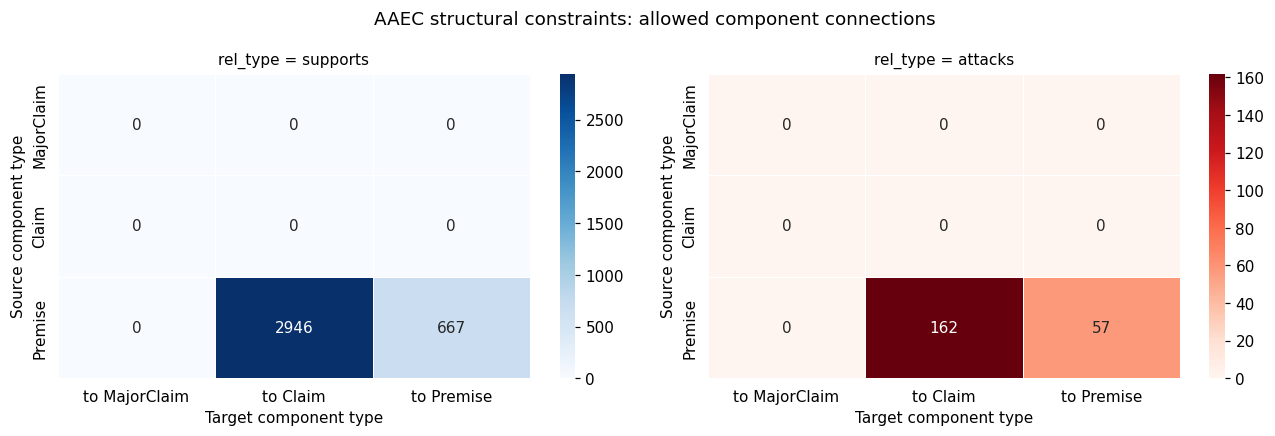

Zero cells = FORBIDDEN in AAEC.
ARIES ignores these constraints: any ADU can relate to any other.


In [24]:
if aaec_essays:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle('AAEC structural constraints: allowed component connections', fontsize=12)

    for ax, rel_t, cmap in zip(axes, ['supports','attacks'], ['Blues','Reds']):
        matrix = np.zeros((3,3), dtype=int)
        for ed in aaec_essays.values():
            comps = ed['components']
            for rel in ed['relations']:
                if rel['rel_type'] != rel_t:
                    continue
                st = comps[rel['source']]['type']
                tt = comps[rel['target']]['type']
                if st in comp_types and tt in comp_types:
                    matrix[comp_types.index(st), comp_types.index(tt)] += 1
        sns.heatmap(matrix, annot=True, fmt='d', cmap=cmap, ax=ax,
                    xticklabels=[f'to {t}' for t in comp_types],
                    yticklabels=comp_types, linewidths=0.5)
        ax.set_title(f'rel_type = {rel_t}', fontsize=10)
        ax.set_xlabel('Target component type')
        ax.set_ylabel('Source component type')

    plt.tight_layout()
    plt.savefig('fig_aaec_constraint_matrix.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Zero cells = FORBIDDEN in AAEC.')
    print('ARIES ignores these constraints: any ADU can relate to any other.')


---
## 8 · Edge direction verification

**Question:** In ARIES, `P1 ──Inference──► P2` — is P1 the premise (source in AAEC)
or the claim (target in AAEC)?

```
AAEC original:  Premise(source) ──supports──► Claim(target)
                                               ↑ this is the node being supported

If ARIES same direction:  P1=Premise  ──Inference──► P2=Claim
If ARIES inverted:        P1=Claim    ──Inference──► P2=Premise
```


In [26]:
if aaec_essays:
    votes = {'same_direction': 0, 'inverted': 0, 'unclear': 0}
    evidence = []

    for arg_text, G_a in list(aries_graphs.items())[:100]:
        # Find matching AAEC essay
        matched = None
        for eid, ed in aaec_essays.items():
            for c in ed['components'].values():
                if c['type']=='MajorClaim' and c['text'][:40] in arg_text:
                    matched = (eid, ed)
                    break
            if matched:
                break
        if not matched:
            continue
        _, ed = matched
        comps = ed['components']

        for rel in ed['relations']:
            src_text = comps[rel['source']]['text'].strip()  # AAEC source (premise)
            tgt_text = comps[rel['target']]['text'].strip()  # AAEC target (claim)
            src_type = comps[rel['source']]['type']
            tgt_type = comps[rel['target']]['type']

            for p1, p2, d in G_a.edges(data=True):
                p1_is_src = src_text[:45] in p1 or p1[:45] in src_text
                p1_is_tgt = tgt_text[:45] in p1 or p1[:45] in tgt_text
                p2_is_tgt = tgt_text[:45] in p2 or p2[:45] in tgt_text
                p2_is_src = src_text[:45] in p2 or p2[:45] in src_text

                if p1_is_src and p2_is_tgt:
                    votes['same_direction'] += 1
                    evidence.append({'direction':'same',
                                     'p1_type':src_type,'p2_type':tgt_type})
                elif p1_is_tgt and p2_is_src:
                    votes['inverted'] += 1
                    evidence.append({'direction':'inverted',
                                     'p1_type':tgt_type,'p2_type':src_type})
                else:
                    votes['unclear'] += 1

    total_v = sum(votes.values())
    print('Edge direction votes:')
    for k,v in votes.items():
        print(f'  {k:<20s}: {v:>4,}  ({100*v/max(total_v,1):.1f}%)')
    print()

    winner = max(votes, key=votes.get)
    if winner == 'same_direction':
        print('CONCLUSION: ARIES preserves AAEC direction')
        print('  P1 = source component (Premise — emits the relation)')
        print('  P2 = target component (Claim/MajorClaim — receives it)')
        print('  out-degree high = Premise-like nodes')
        print('  in-degree high  = Claim/MajorClaim-like nodes')
    elif winner == 'inverted':
        print('CONCLUSION: ARIES INVERTS AAEC direction')
        print('  P1 = target component (Claim/MajorClaim)')
        print('  P2 = source component (Premise)')
        print('  out-degree high = Claim/MajorClaim-like nodes (central claims)')
        print('  in-degree high  = Premise-like nodes')
    print()

    if evidence:
        ev_df = pd.DataFrame(evidence)
        print('Component type of P1 in matched edges:')
        print(ev_df.groupby(['direction','p1_type']).size().to_string())


Edge direction votes:
  same_direction      :    0  (0.0%)
  inverted            :  958  (6.5%)
  unclear             : 13,740  (93.5%)


Component type of P1 in matched edges:
direction  p1_type
inverted   Claim      810
           Premise    148


---
## 9 · Summary


In [27]:
print('=' * 65)
print('AAEC vs ARIES — SUMMARY')
print('=' * 65)
print()
print('AAEC in ARIES:')
print(f'  Essays           : {n_essays:>5,}')
print(f'  ADU pairs        : {n_pairs:>5,}')
print(f'  Real relations   : {n_real:>5,}  ({100*n_real/n_pairs:.1f}%)')
print(f'  Isolated nodes   : {sum(iso_l):>5,}  ({100*sum(iso_l)/sum(n_nodes_l):.1f}% of all nodes)')
print()
print('What ARIES preserves:')
print('  ✓ ADU texts (proposition_1, proposition_2)')
print('  ✓ Relation existence (Inference / Conflict / Neutral)')
print('  ✓ Full document context (argument column)')
print()
print('What ARIES loses:')
print('  ✗ Component type  (MajorClaim / Claim / Premise)')
print('  ✗ Structural constraints (which types can connect)')
print('  ✗ Stance attribute (For / Against)')
print('  ✗ Character offsets (exact position in essay)')
print()
print('Why isolated nodes exist:')
print('  H1 (main cause): ARIES includes non-argumentative sentences')
print('     that are present in the essay text but were NOT annotated')
print('     as MajorClaim/Claim/Premise in the original AAEC.')
print('  H2 (secondary):  Text normalisation differences between')
print('     ARIES CSV and original .ann files may break exact matching.')
print()
print('Edge direction: see Section 8 output.')
print('=' * 65)


AAEC vs ARIES — SUMMARY

AAEC in ARIES:
  Essays           :   402
  ADU pairs        : 15,217
  Real relations   : 5,338  (35.1%)
  Isolated nodes   :   290  (4.8% of all nodes)

What ARIES preserves:
  ✓ ADU texts (proposition_1, proposition_2)
  ✓ Relation existence (Inference / Conflict / Neutral)
  ✓ Full document context (argument column)

What ARIES loses:
  ✗ Component type  (MajorClaim / Claim / Premise)
  ✗ Structural constraints (which types can connect)
  ✗ Stance attribute (For / Against)
  ✗ Character offsets (exact position in essay)

Why isolated nodes exist:
  H1 (main cause): ARIES includes non-argumentative sentences
     that are present in the essay text but were NOT annotated
     as MajorClaim/Claim/Premise in the original AAEC.
  H2 (secondary):  Text normalisation differences between
     ARIES CSV and original .ann files may break exact matching.

Edge direction: see Section 8 output.


---
## Next steps

| Question | Notebook |
|---|---|
| Can we recover component types from graph topology? | 04_component_recovery.ipynb |
| Does direction finding hold for MTC and CDCP? | Repeat Section 8 for other corpora |
| How to handle isolated nodes in a GNN? | 05_modelling_features.ipynb |
